# 19 Energetics and the shattering-flare budget

The fluxes in the shared tables are observed values in 10-1000 keV. To compare episodes, and to ask whether a precursor's energy is possible for a resonant shattering flare, I need isotropic energies and luminosities in the rest frame, 1-10,000 keV.

1. k-correction, E_iso and L_iso for every episode of both known bursts
2. A check against Troja et al. (2022) and Dichiara et al. (2023)
3. The Amati plane, with the published tracks for both classes
4. The energy budget of a shattering flare, using Dichiara's Sec. 3

For a window with flux F (10-1000 keV) lasting T, in the observer frame, L_iso = 4 pi D_L^2 F k and E_iso = L_iso T / (1 + z), where k is the integral of E N(E) over 1/(1+z) to 10000/(1+z) keV divided by the same integral over 10-1000 keV. The spectral shape in each window is the one in the shared tables.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy import units as u
from astropy.cosmology import Planck18
from scipy.integrate import quad

from settings import FIGURE_DIR, WINDOWS_FILE
from spectral_fit_tools import BandLowBreak
from gdt.core.spectra.functions import Band, Comptonized

pd.set_option("display.width", 220)
SHARED = WINDOWS_FILE.parent
KEV = 1.602176634e-9       # erg
table_230 = pd.read_csv(SHARED / "epeak_230307A.csv").set_index("label")
table_211 = pd.read_csv(SHARED / "epeak_211211A.csv").set_index("label")
REDSHIFT = {"GRB230307A": 0.065, "GRB211211A": 0.076}
DISTANCE = {b: Planck18.luminosity_distance(z).to(u.cm).value for b, z in REDSHIFT.items()}
print({b: round(Planck18.luminosity_distance(z).value) for b, z in REDSHIFT.items()}, "Mpc, Planck 2018")

def shape_of(row):
    '''N(E) up to a constant, from the model and parameters in a row of the E_peak tables.'''
    if row.model == "BandLowBreak":
        found = re.search(r"break at ([\d.]+) keV, alpha1 (-?[\d.]+) below it, alpha2 (-?[\d.]+) above", row.notes)
        eb, a1, a2 = (float(x) for x in found.groups())
        function, params = BandLowBreak(), [1.0, eb, a1, a2, row.Epeak_keV, min(row.beta, -2.05), 2.0, 100.0]
    elif row.model == "Band":
        function, params = Band(), [1.0, row.Epeak_keV, row.alpha, min(row.beta, -2.05), 100.0]
    else:
        function, params = Comptonized(), [1.0, row.Epeak_keV, row.alpha, 100.0]
    return lambda e: function.eval(params, np.atleast_1d(np.asarray(e, float)))[0]

def k_correction(shape, z):
    upper = quad(lambda x: np.exp(2 * x) * shape(np.exp(x)), np.log(1.0 / (1 + z)), np.log(1e4 / (1 + z)), limit=300)[0]
    lower = quad(lambda x: np.exp(2 * x) * shape(np.exp(x)), np.log(10.0), np.log(1000.0), limit=300)[0]
    return upper / lower

def energetics(burst, row):
    z, d = REDSHIFT[burst], DISTANCE[burst]
    k = k_correction(shape_of(row), z)
    duration = row.t_stop - row.t_start
    luminosity = 4 * np.pi * d**2 * row.flux_10_1000keV_erg_cm2_s * k
    return dict(burst=burst, label=row.name, t_start=row.t_start, t_stop=row.t_stop, model=row.model, Ep_obs=row.Epeak_keV, Ep_rest=row.Epeak_keV * (1 + z), flux=row.flux_10_1000keV_erg_cm2_s, flux_err=row.flux_err, k=k,
                L_iso=luminosity, E_iso=luminosity * duration / (1 + z), L_iso_no_k=4 * np.pi * d**2 * row.flux_10_1000keV_erg_cm2_s, frac_err=row.flux_err / row.flux_10_1000keV_erg_cm2_s)

rows = [energetics("GRB230307A", table_230.loc[label]) for label in table_230.index]
rows += [energetics("GRB211211A", table_211.loc[label]) for label in table_211.index]
energy = pd.DataFrame(rows).set_index(["burst", "label"])
energy.to_csv(SHARED / "energetics_known_bursts.csv", float_format="%.5g")
energy[["t_start", "t_stop", "model", "Ep_rest", "flux", "k", "L_iso", "E_iso"]]

{'GRB230307A': 302, 'GRB211211A': 356} Mpc, Planck 2018


t_start  t_stop         model      Ep_rest          flux         k         L_iso         E_iso
burst      label                                                                                                   
GRB230307A pre        -0.064   0.320          Band   181.369500  3.322610e-05  1.116093  4.047224e+50  1.459281e+50
           m01         0.320   3.000          Band   973.453665  1.299920e-04  1.552428  2.202447e+51  5.542309e+51
           m02         7.000   9.000          Band  1030.217100  1.750980e-04  1.616564  3.089239e+51  5.801388e+51
           m03         9.000  11.000          Band  1007.044830  1.572460e-04  1.581196  2.713581e+51  5.095927e+51
           m04        11.000  13.000          Band   854.294010  1.164730e-04  1.433179  1.821810e+51  3.421240e+51
           m05        13.000  15.000          Band   831.681930  9.463760e-05  1.421681  1.468397e+51  2.757552e+51
           m06        15.000  18.500          Band   671.931930  4.818370e-05  1.314724  6.913729e+50  2.272117e+51
           m07        18.500  22.000          Band   655.372245  4.547700e-05  1.312104  6.512351e+50  2.140209e+51
           m08        22.000  25.500          Band   499.139940  3.539940e-05  1.219698  4.712221e+50  1.548617e+51
           m09        25.500  29.000          Band   429.179025  2.480740e-05  1.253229  3.393043e+50  1.115084e+51
           m10        29.000  32.500          Band   342.790485  1.180620e-05  1.217407  1.568641e+50  5.155157e+50
           m11        32.500  40.000          Band   247.603980  9.885560e-06  1.192836  1.286944e+50  9.062984e+50
           t1_07_18    7.000  18.000          Band   935.462985  1.125260e-04  1.505894  1.849375e+51  1.910152e+52
           t1_18_40   18.000  40.000          Band   479.565240  2.207900e-05  1.252288  3.017597e+50  6.233534e+51
GRB211211A pre        -0.016   0.432   Comptonized    71.820956  1.216920e-06  1.161799  2.141774e+49  8.917425e+48
           g00_02      0.000   2.000  BandLowBreak  1684.833080  4.962980e-06  1.925745  1.447844e+50  2.691160e+50
           g02_04      2.000   4.000  BandLowBreak  1304.262640  3.999490e-05  1.799589  1.090332e+51  2.026639e+51
           g04_06      4.000   6.000  BandLowBreak   891.478912  2.649550e-05  1.537538  6.171325e+50  1.147086e+51
           g06_08      6.000   8.000  BandLowBreak  1729.035160  8.410930e-05  2.078022  2.647736e+51  4.921443e+51
           g08_10      8.000  10.000  BandLowBreak  1353.328240  2.580300e-05  1.737327  6.790977e+50  1.262263e+51
           g10_12     10.000  12.000  BandLowBreak   573.436984  9.443250e-06  1.405237  2.010258e+50  3.736538e+50
           g12_16     12.000  16.000   Comptonized   218.804600  2.374020e-06  1.160131  4.172265e+49  1.551028e+50
           g16_18     16.000  18.000  BandLowBreak   398.878580  7.570410e-06  1.287457  1.476497e+50  2.744419e+50
           g18_20     18.000  20.000  BandLowBreak   638.219716  1.174110e-05  1.362352  2.423142e+50  4.503981e+50
           g20_22     20.000  22.000  BandLowBreak   356.743496  9.252410e-06  1.249635  1.751534e+50  3.255639e+50
           g22_24     22.000  24.000  BandLowBreak   363.496472  9.958510e-06  1.207510  1.821654e+50  3.385973e+50
           g24_26     24.000  26.000  BandLowBreak   330.296492  9.211670e-06  1.183099  1.650972e+50  3.068722e+50
           g26_30     26.000  30.000          Band    70.230950  3.786680e-06  1.441162  8.267079e+49  3.073263e+50
           g30_34     30.000  34.000          Band    57.532536  2.518940e-06  1.401893  5.349499e+49  1.988661e+50
           g34_38     34.000  38.000  BandLowBreak   116.289776  3.101740e-06  1.157109  5.437011e+49  2.021194e+50
           g38_42     38.000  42.000          Band    67.704395  2.246680e-06  1.368850  4.658839e+49  1.731910e+50
           g42_46     42.000  46.000          Band    46.499448  1.315580e-06  1.350374  2.691236e+49  1.000460e+50
           g46_50     46.000  50.000          Band    45.540194  1.241510e-06

The k-correction matters most where E_peak is high: from 1.2 to 1.6 for 230307A and up to 2.1 for 211211A's two-break windows. It is 1.12 and 1.16 for the two precursors, whose peaks sit well inside 10-1000 keV. These energies carry the model dependence of each window, and the fluxes carry the instrument uncertainty from notebook 15, so read them as good to a few tens of percent.

## 2. Against the published values

Dichiara quote L_iso of about 3.6e50 erg/s for GRB 230307A's precursor. Troja et al. quote fluences at 10-1000 keV for GRB 211211A: 3.7e-4 erg/cm2 for the main emission, about 10 s long, which is their ~5e51 erg at 346 Mpc, and 5e-5 erg/cm2 for the extended emission, their ~7e50 erg. Their energies have no k-correction: 4 pi D^2 S / (1 + z) reproduces both. So I compare fluences, using my 0-12 s slices for the main emission and my 27-66 s window for the extended emission (the times in their text are approximate). For 230307A the sum leaves out 3-7 s.

In [2]:
pre = energy.loc[("GRB230307A", "pre")]
d_291 = (291 * u.Mpc).to(u.cm).value
d_346 = (346 * u.Mpc).to(u.cm).value
print(f"230307A precursor: flux x 4 pi (291 Mpc)^2 = {4 * np.pi * d_291**2 * pre.flux:.3e} erg/s (Dichiara ~3.6e50); mine at {REDSHIFT['GRB230307A']}: no k {pre.L_iso_no_k:.3e}, with k {pre.L_iso:.3e}, E_iso {pre.E_iso:.3e} erg")
slices = energy.loc["GRB211211A"]
g = slices[slices.index.str.startswith("g")]
main = g[g.t_stop <= 12.0]
main_fluence = np.sum(main.flux * (main.t_stop - main.t_start))
tail = slices.loc["f2_27_66"]
tail_fluence = tail.flux * (tail.t_stop - tail.t_start)
no_k = lambda fluence: 4 * np.pi * d_346**2 * fluence / (1 + REDSHIFT["GRB211211A"])
print(f"211211A main 0-12 s: fluence {main_fluence:.3e} erg/cm2 (Troja 3.7e-4), no k at 346 Mpc {no_k(main_fluence):.3e} erg (Troja ~5e51); with k at {REDSHIFT['GRB211211A']}: E_iso {main.E_iso.sum():.3e} erg")
print(f"211211A extended 27-66 s: fluence {tail_fluence:.3e} erg/cm2 (Troja ~5e-5), no k at 346 Mpc {no_k(tail_fluence):.3e} erg (Troja ~7e50); with k: E_iso {tail.E_iso:.3e} erg")
print(f"211211A precursor: L_iso {slices.L_iso['pre']:.3e} erg/s, E_iso {slices.E_iso['pre']:.3e} erg")
m = energy.loc["GRB230307A"]
tr = m[m.index.str.match(r"m\d\d")]
print(f"230307A m01-m11: E_iso {tr.E_iso.sum():.3e} erg, without 3-7 s and after 40 s; precursor / that = {pre.E_iso / tr.E_iso.sum():.4f}; 211211A precursor / main = {slices.E_iso['pre'] / main.E_iso.sum():.4f}")

230307A precursor: flux x 4 pi (291 Mpc)^2 = 3.366e+50 erg/s (Dichiara ~3.6e50); mine at 0.065: no k 3.626e+50, with k 4.047e+50, E_iso 1.459e+50 erg
211211A main 0-12 s: fluence 3.816e-04 erg/cm2 (Troja 3.7e-4), no k at 346 Mpc 5.080e+51 erg (Troja ~5e51); with k at 0.076: E_iso 1.000e+52 erg
211211A extended 27-66 s: fluence 6.132e-05 erg/cm2 (Troja ~5e-5), no k at 346 Mpc 8.163e+50 erg (Troja ~7e50); with k: E_iso 1.125e+51 erg
211211A precursor: L_iso 2.142e+49 erg/s, E_iso 8.917e+48 erg
230307A m01-m11: E_iso 3.112e+52 erg, without 3-7 s and after 40 s; precursor / that = 0.0047; 211211A precursor / main = 0.0009


The numbers line up. My 0-12 s fluence is within about 3% of Troja et al.'s and my extended-emission fluence is about 23% above theirs, with their exact times unknown. For 230307A's precursor I get 3.37e50 erg/s at 291 Mpc, against their ~3.6e50, and 3.63e50 erg/s at the Planck distance of 302 Mpc.

With the k-correction, the precursor of 230307A carries 1.5e50 erg, 0.5% of the emission in the Table 2 windows, and 211211A's carries 8.9e48 erg, 0.09% of its 0-12 s emission. Those are isotropic energies; the true ones are lower if the emission is beamed.

## 3. The Amati plane

Minaev and Pozanenko (2020, MNRAS) fit lg(E_p,i / 100 keV) = a lg(E_iso / 10^51 erg) + b: a = 0.41, b = 0.83 for type I and a = 0.43, b = -0.24 for type II, with their mean of two fitting methods. The tracks are for whole bursts, so a single precursor or slice isn't strictly a point on them. I plot the whole main emission and the precursors for comparison.

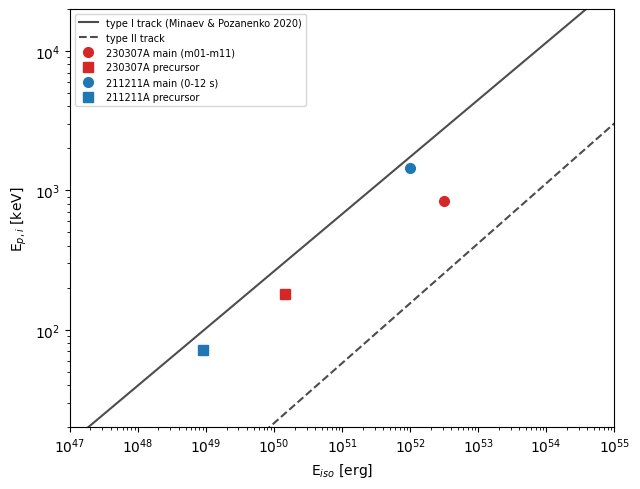

,E_iso,Ep_i,dex_from_type_I,dex_from_type_II
point,,,,
230307A main (m01-m11),3.111626e+52,845.276908,-0.515126,0.525014
230307A precursor,1.459281e+50,181.369500,-0.228733,0.857985
211211A main (0-12 s),1.000020e+52,1455.086673,-0.077115,0.972885
211211A precursor,8.917425e+48,71.820956,-0.133347,0.977648


In [3]:
main_230 = tr[tr.t_stop <= 40.0]
points = [("230307A main (m01-m11)", main_230.E_iso.sum(), np.sum(main_230.Ep_rest * main_230.E_iso) / main_230.E_iso.sum(), "tab:red", "o"),
          ("230307A precursor", pre.E_iso, pre.Ep_rest, "tab:red", "s"),
          ("211211A main (0-12 s)", main.E_iso.sum(), np.sum(main.Ep_rest * main.E_iso) / main.E_iso.sum(), "tab:blue", "o"),
          ("211211A precursor", slices.E_iso["pre"], slices.Ep_rest["pre"], "tab:blue", "s")]
x = np.logspace(47, 55, 50)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(x, 100 * 10**(0.41 * np.log10(x / 1e51) + 0.83), color="0.3", label="type I track (Minaev & Pozanenko 2020)")
ax.plot(x, 100 * 10**(0.43 * np.log10(x / 1e51) - 0.24), color="0.3", ls="--", label="type II track")
rows = []
for name, e_iso, ep_i, colour, marker in points:
    ax.plot(e_iso, ep_i, marker, color=colour, ms=7, label=name)
    y = np.log10(ep_i / 100)
    rows.append(dict(point=name, E_iso=e_iso, Ep_i=ep_i, dex_from_type_I=y - (0.41 * np.log10(e_iso / 1e51) + 0.83), dex_from_type_II=y - (0.43 * np.log10(e_iso / 1e51) - 0.24)))
ax.set(xscale="log", yscale="log", xlabel="E$_{iso}$ [erg]", ylabel="E$_{p,i}$ [keV]", xlim=(1e47, 1e55), ylim=(20, 2e4))
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "19_amati_plane.png", dpi=200)
plt.show()
pd.DataFrame(rows).set_index("point")

211211A's main emission sits on the type I track (0.08 dex below it) and about 1 dex above the type II track, as Troja et al. show. 230307A's comes out halfway between the two tracks (0.5 dex from each), partly because this sum leaves out 3-7 s, and its E_p,i here is an energy-weighted mean of Band values, so I wouldn't lean on that placing. Both precursors lie within about 0.25 dex of the type I track and nearly 1 dex above type II. That is suggestive, but these tracks were fitted to whole bursts, and whether a precursor should follow them at all isn't clear.

## 4. The shattering-flare budget

Dichiara's Sec. 3: the energy available is set by the tidal energy transfer rate, up to about 1e50 erg/s for the fiducial values, with an assumed gamma-ray efficiency of 20%. So the tidal rate a precursor needs is L_iso / 0.2. The surface field also limits the luminosity: Tsang (2013, Eq. 9) has L_max proportional to B^2, and Dichiara's Fig. 4 reaches 3.6e50 erg/s at 1.2e15 G. Scaling from that point, B_min = 1.2e15 G x (L_iso / 3.6e50 erg/s)^(1/2). I use their own L_iso definition for this (10-1000 keV, no k-correction) so the scaling stays consistent with their point, and show the k-corrected value next to it.

In [4]:
FIDUCIAL = 1e50
rows = []
for name, row in (("230307A precursor", pre), ("211211A precursor", slices.loc["pre"])):
    rows.append(dict(precursor=name, L_iso_no_k=row.L_iso_no_k, L_iso_k=row.L_iso, tidal_rate_needed=row.L_iso_no_k / 0.2, times_fiducial=row.L_iso_no_k / 0.2 / FIDUCIAL, B_min_G=1.2e15 * np.sqrt(row.L_iso_no_k / 3.6e50),
                     tidal_rate_needed_k=row.L_iso / 0.2, B_min_k_G=1.2e15 * np.sqrt(row.L_iso / 3.6e50)))
budget = pd.DataFrame(rows).set_index("precursor")
budget

,L_iso_no_k,L_iso_k,tidal_rate_needed,times_fiducial,B_min_G,tidal_rate_needed_k,B_min_k_G
precursor,,,,,,,
230307A precursor,3.626243e+50,4.047224e+50,1.813122e+51,18.131216,1.204366e+15,2.023612e+51,1.272356e+15
211211A precursor,1.843498e+49,2.141774e+49,9.217488e+49,0.921749,2.715509e+14,1.070887e+50,2.926960e+14


The two precursors differ a lot. GRB 211211A's needs a tidal energy rate of 0.9e50 erg/s at 20% efficiency, right at the fiducial value of up to ~1e50 erg/s, and a field of about 2.7e14 G. GRB 230307A's needs 1.8e51 erg/s, 18 times the fiducial value, and about 1.2e15 G, which is Dichiara's number by construction, since the scaling starts from their point. They say an order of magnitude more might be possible if the breaking strain and tidal overlap are a factor of a few larger than the conservative values. So by this budget 211211A's precursor just fits and 230307A's is a stretch.

The limits of this: it assumes L_max goes as B^2 all the way down, read from their Fig. 4 and Tsang (2013); it assumes 20% efficiency; and the emission is taken as isotropic, while a beamed flare would need less. With the k-correction the rates go up by 12-16% and the field by 6-8%, which puts 211211A's at 1.07 times the fiducial value. This is a calculation to discuss with my supervisor, since the model is my supervisor's.